# Prédire la gravité d'un signalement — XGBoost

Module 7. Même table de features et même découpage temporel que les modèles BigQuery ML (`ml/bqml_serious.sql`) pour pouvoir les comparer.

- **Source** : `dbt_dev_marts.ml_features_serious` (aucune colonne de gravité, d'issue ni de terme de réaction : pas de fuite de données)
- **Entraînement** : avril et mai 2026 · **Test** : juin 2026
- **Cible** : `is_serious`

> Données déclaratives FAERS : le modèle aide à prioriser la revue des signalements, il ne dit rien de la causalité.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from google.cloud import bigquery
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from xgboost import XGBClassifier

PROJECT = "pharmaco-openfda-pg"
TEST_START = "2026-06-01"
bq = bigquery.Client(project=PROJECT, location="EU")

Matplotlib is building the font cache; this may take a moment.


## 1. Chargement des features

In [2]:
df = bq.query(f"select * from `{PROJECT}.dbt_dev_marts.ml_features_serious`").to_dataframe(
    create_bqstorage_client=False
)
df["receive_date"] = pd.to_datetime(df["receive_date"])
print(df.shape)
df.head()

(352949, 15)


,safety_report_id,receive_date,age_years,age_group,sex,reporter_type,is_health_professional,country_group,drug_count,suspect_drug_count,has_interaction,primary_suspect_route,primary_suspect_pharm_class,receive_month,is_serious
0,26789775,2026-05-21,81.0,80+,Homme,Inconnu,False,OTHER,2,2,False,ORAL,Complement 5a Receptor Antagonist [EPC],05,True
1,26768517,2026-05-15,NaN,Inconnu,Femme,Inconnu,False,OTHER,1,1,False,ORAL,Complement 5a Receptor Antagonist [EPC],05,True
2,26740037,2026-05-08,83.0,80+,Femme,Inconnu,False,OTHER,1,1,False,ORAL,Complement 5a Receptor Antagonist [EPC],05,True
3,26719230,2026-05-05,78.0,65-79,Femme,Inconnu,False,OTHER,1,1,False,ORAL,Complement 5a Receptor Antagonist [EPC],05,True
4,26727080,2026-05-07,64.0,45-64,Femme,Inconnu,False,OTHER,1,1,False,ORAL,Complement 5a Receptor Antagonist [EPC],05,True


## 2. Découpage temporel et encodage

On entraîne sur le passé et on évalue sur le mois suivant, comme en conditions réelles. Les variables catégorielles sont passées à XGBoost en type `category` (encodage natif).

In [3]:
CATEGORICAL = [
    "age_group", "sex", "reporter_type", "country_group",
    "primary_suspect_route", "primary_suspect_pharm_class",
]
NUMERIC = ["age_years", "drug_count", "suspect_drug_count"]
BOOLEAN = ["is_health_professional", "has_interaction"]
FEATURES = CATEGORICAL + NUMERIC + BOOLEAN

X = df[FEATURES].copy()
for col in CATEGORICAL:
    X[col] = X[col].astype("category")
for col in NUMERIC:
    X[col] = X[col].astype("float64")
for col in BOOLEAN:
    X[col] = X[col].astype("int8")
y = df["is_serious"].astype(int)

is_test = df["receive_date"] >= TEST_START
X_train, X_test, y_train, y_test = X[~is_test], X[is_test], y[~is_test], y[is_test]
print(f"train : {len(X_train):,} lignes · test : {len(X_test):,} lignes")

train : 236,133 lignes · test : 116,816 lignes


## 3. Baseline

In [4]:
baseline = y_test.mean()
print(f"Part de signalements graves en test : {baseline:.1%}")
print(f"Exactitude d'un modèle qui prédit toujours « grave » : {baseline:.1%}")

Part de signalements graves en test : 50.6%
Exactitude d'un modèle qui prédit toujours « grave » : 50.6%


## 4. Entraînement XGBoost (classes pondérées)

In [5]:
model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    enable_categorical=True,
    tree_method="hist",
    scale_pos_weight=(y_train == 0).sum() / (y_train == 1).sum(),
    eval_metric="auc",
    random_state=42,
)
model.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'auc'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


## 5. Évaluation sur la période de test (seuil 0,5)

In [6]:
proba = model.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)
xgb_metrics = {
    "model": "xgboost",
    "roc_auc": roc_auc_score(y_test, proba),
    "accuracy": accuracy_score(y_test, pred),
    "precision": precision_score(y_test, pred),
    "recall": recall_score(y_test, pred),
    "f1_score": f1_score(y_test, pred),
}
pd.Series(xgb_metrics)

model         xgboost
roc_auc      0.859423
accuracy     0.802313
precision     0.80452
recall       0.804779
f1_score     0.804649
dtype: object

## 6. Comparaison des trois modèles

Les métriques BigQuery ML sont lues avec `ML.EVALUATE` sur la même période de test.

In [7]:
bqml = bq.query(f"""
    select 'bqml_logistic_reg' as model, roc_auc, accuracy, precision, recall, f1_score
    from ml.evaluate(model `{PROJECT}.ml.serious_logreg`,
        (select * from `{PROJECT}.dbt_dev_marts.ml_features_serious` where receive_date >= '{TEST_START}'))
    union all
    select 'bqml_boosted_tree', roc_auc, accuracy, precision, recall, f1_score
    from ml.evaluate(model `{PROJECT}.ml.serious_boosted_tree`,
        (select * from `{PROJECT}.dbt_dev_marts.ml_features_serious` where receive_date >= '{TEST_START}'))
""").to_dataframe(create_bqstorage_client=False)

baseline_row = {"model": "baseline (toujours grave)", "roc_auc": 0.5, "accuracy": baseline,
                "precision": baseline, "recall": 1.0, "f1_score": 2 * baseline / (1 + baseline)}
comparison = pd.concat([pd.DataFrame([baseline_row]), bqml, pd.DataFrame([xgb_metrics])], ignore_index=True)
comparison.set_index("model").astype(float).round(3)

,roc_auc,accuracy,precision,recall,f1_score
model,,,,,
baseline (toujours grave),0.500,0.506,0.506,1.000,0.672
bqml_boosted_tree,0.898,0.817,0.834,0.796,0.815
bqml_logistic_reg,0.862,0.782,0.775,0.801,0.788
xgboost,0.859,0.802,0.805,0.805,0.805


## 7. Variables les plus importantes (gain XGBoost)

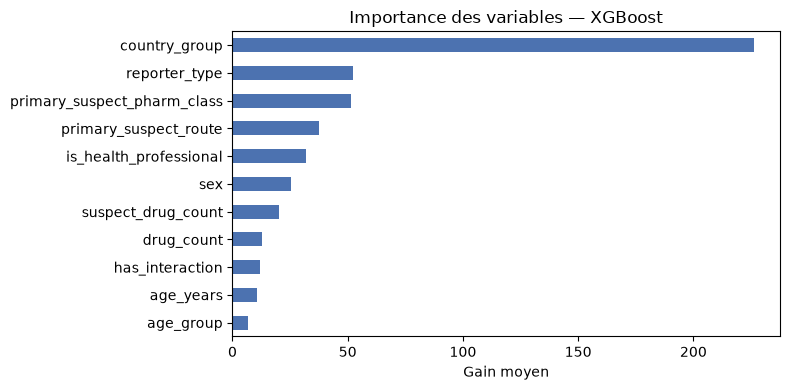

country_group                  226.3
reporter_type                   52.1
primary_suspect_pharm_class     51.2
primary_suspect_route           37.8
is_health_professional          31.8
sex                             25.4
suspect_drug_count              20.2
drug_count                      12.8
has_interaction                 12.0
age_years                       10.7
age_group                        6.9
dtype: float64

In [8]:
importance = (
    pd.Series(model.get_booster().get_score(importance_type="gain"))
    .sort_values(ascending=True)
)
ax = importance.plot.barh(figsize=(8, 4), color="#4C72B0")
ax.set_xlabel("Gain moyen")
ax.set_title("Importance des variables — XGBoost")
plt.tight_layout()
plt.show()
importance.sort_values(ascending=False).round(1)

## 8. Taux de signalements graves selon les variables principales

In [9]:
for col in ["country_group", "reporter_type", "age_group"]:
    table = (
        df.groupby(col, observed=True)["is_serious"]
        .agg(signalements="size", taux_graves="mean")
        .sort_values("signalements", ascending=False)
        .head(8)
    )
    display(table.style.format({"signalements": "{:,}", "taux_graves": "{:.1%}"}))

,signalements,taux_graves
country_group,,
US,"210,542",31.0%
OTHER,"48,758",59.3%
EU,"34,109",98.0%
GB,"12,935",98.5%
CA,"12,838",97.8%
JP,"10,032",97.0%
CN,"8,295",98.7%
CO,"2,454",86.1%


,signalements,taux_graves
reporter_type,,
Consommateur,"196,081",35.4%
Autre professionnel de santé,"71,359",64.6%
Médecin,"55,281",83.0%
Pharmacien,"17,883",70.3%
Avocat,"9,671",99.2%
Inconnu,"2,674",56.1%


,signalements,taux_graves
age_group,,
Inconnu,"139,065",43.9%
45-64,"66,476",57.8%
65-79,"65,877",59.2%
18-44,"44,174",56.0%
80+,"22,274",66.4%
0-17,"15,083",47.5%


## 9. Limites

- **Données déclaratives** : la gravité est celle déclarée, pas une mesure clinique.
- **Biais de déclaration** : hors États-Unis, seuls les cas graves sont transmis à la FDA ; le pays et le type de déclarant (avocats, contentieux) prédisent la gravité pour des raisons réglementaires, pas médicales.
- **Période courte** : 2 mois d'entraînement et 1 mois de test, pas de saisonnalité exploitable.
- **Pas de causalité** : le modèle priorise des signalements à revoir, il n'établit aucun lien entre un médicament et une réaction.